# A1 EDA: power vs irradiance, and gaps / offline events

Stage 6, A1's two questions (§6 of the design doc):

- **Q1.** How do AC power and irradiance relate, per inverter? *Informs: expected-power model, night-time threshold.*
- **Q2.** Where are the gaps / offline events? *Informs: imputation vs `is_offline`.*

All analysis code lives in `src/eda.py`; this notebook only calls it. Input: `data/processed/hkust_15min_v1.parquet` (run `python -m src.prepare_data` first). Figures are saved to `reports/figures/`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
import pandas as pd
from src import eda

pd.set_option("display.width", 160)
eda.set_style()
df = eda.load()
print(f"{len(df):,} rows, {df['inverter_id'].nunique()} inverters")

1,588,901 rows, 44 inverters


## Q1. AC power vs irradiance

Power is divided by each inverter's DC capacity (kWp from the Brick metadata) to give **specific yield** (kW per kWp), so inverters of different sizes are comparable. A healthy array gives a roughly straight line through the origin.

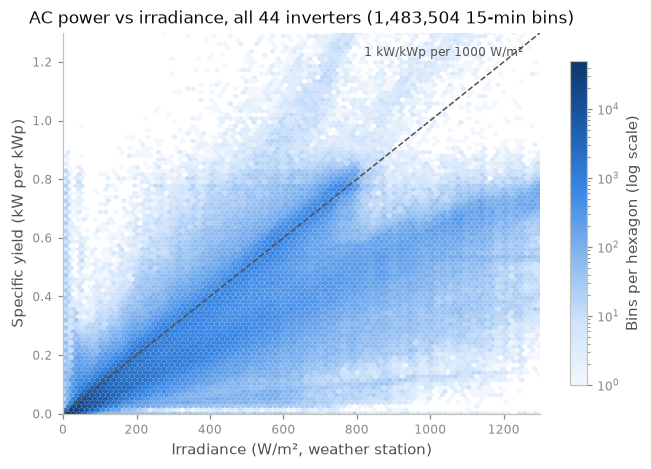

In [2]:
fig = eda.plot_yield_vs_irradiance(df)
eda.save(fig, "a1_q1_yield_vs_irradiance");

**Finding.** The main cloud is a straight line through the origin, as expected. Outside it there are:
- a band near **0 kW/kWp at high irradiance**: the inverter is producing nothing in full sun, which is an outage or a fault;
- a **flat ceiling around 0.75-0.8 kW/kWp**: inverter clipping (AC rating below DC capacity);
- points **above 1 kW/kWp**, which are physically unlikely; see Zone D Inverter 2 below;
- **two separate branches**, explained by the sensor change below.

**Decision.** The expected-power model (B1, Option B) must handle clipping, either as a non-linear model or with capacity limits. Points that are zero output at high irradiance are the cases the health score is meant to catch.

In [3]:
fits = eda.per_inverter_fit(df)
fits

,inverter_id,n_bins,pearson_r,slope_kw_per_kwp,p99_specific_yield,capacity_kwp
0,zone_d_inverter_1,15600,0.915,0.318,0.420,68.620003
1,ug_hall2_2f_inverter,34485,0.747,0.425,0.658,23.400000
2,library_inverter_3,22002,0.680,0.469,0.760,56.240002
3,s_h_ho_sports_hall_inverter_2,28743,0.681,0.482,0.772,27.299999
4,zone_j2_inverter,26557,0.696,0.488,0.668,63.875000
5,s_h_ho_sports_hall_inverter_1,28743,0.743,0.498,0.743,21.840000
6,zone_l2_inverter,19696,0.839,0.533,0.610,12.045000
7,zone_a2_inverter_2,9406,0.894,0.540,0.739,73.040001
8,zone_a2_inverter_3,9419,0.911,0.553,0.753,66.400002
9,sq_block_p_inverter,6910,0.921,0.585,0.812,37.130001


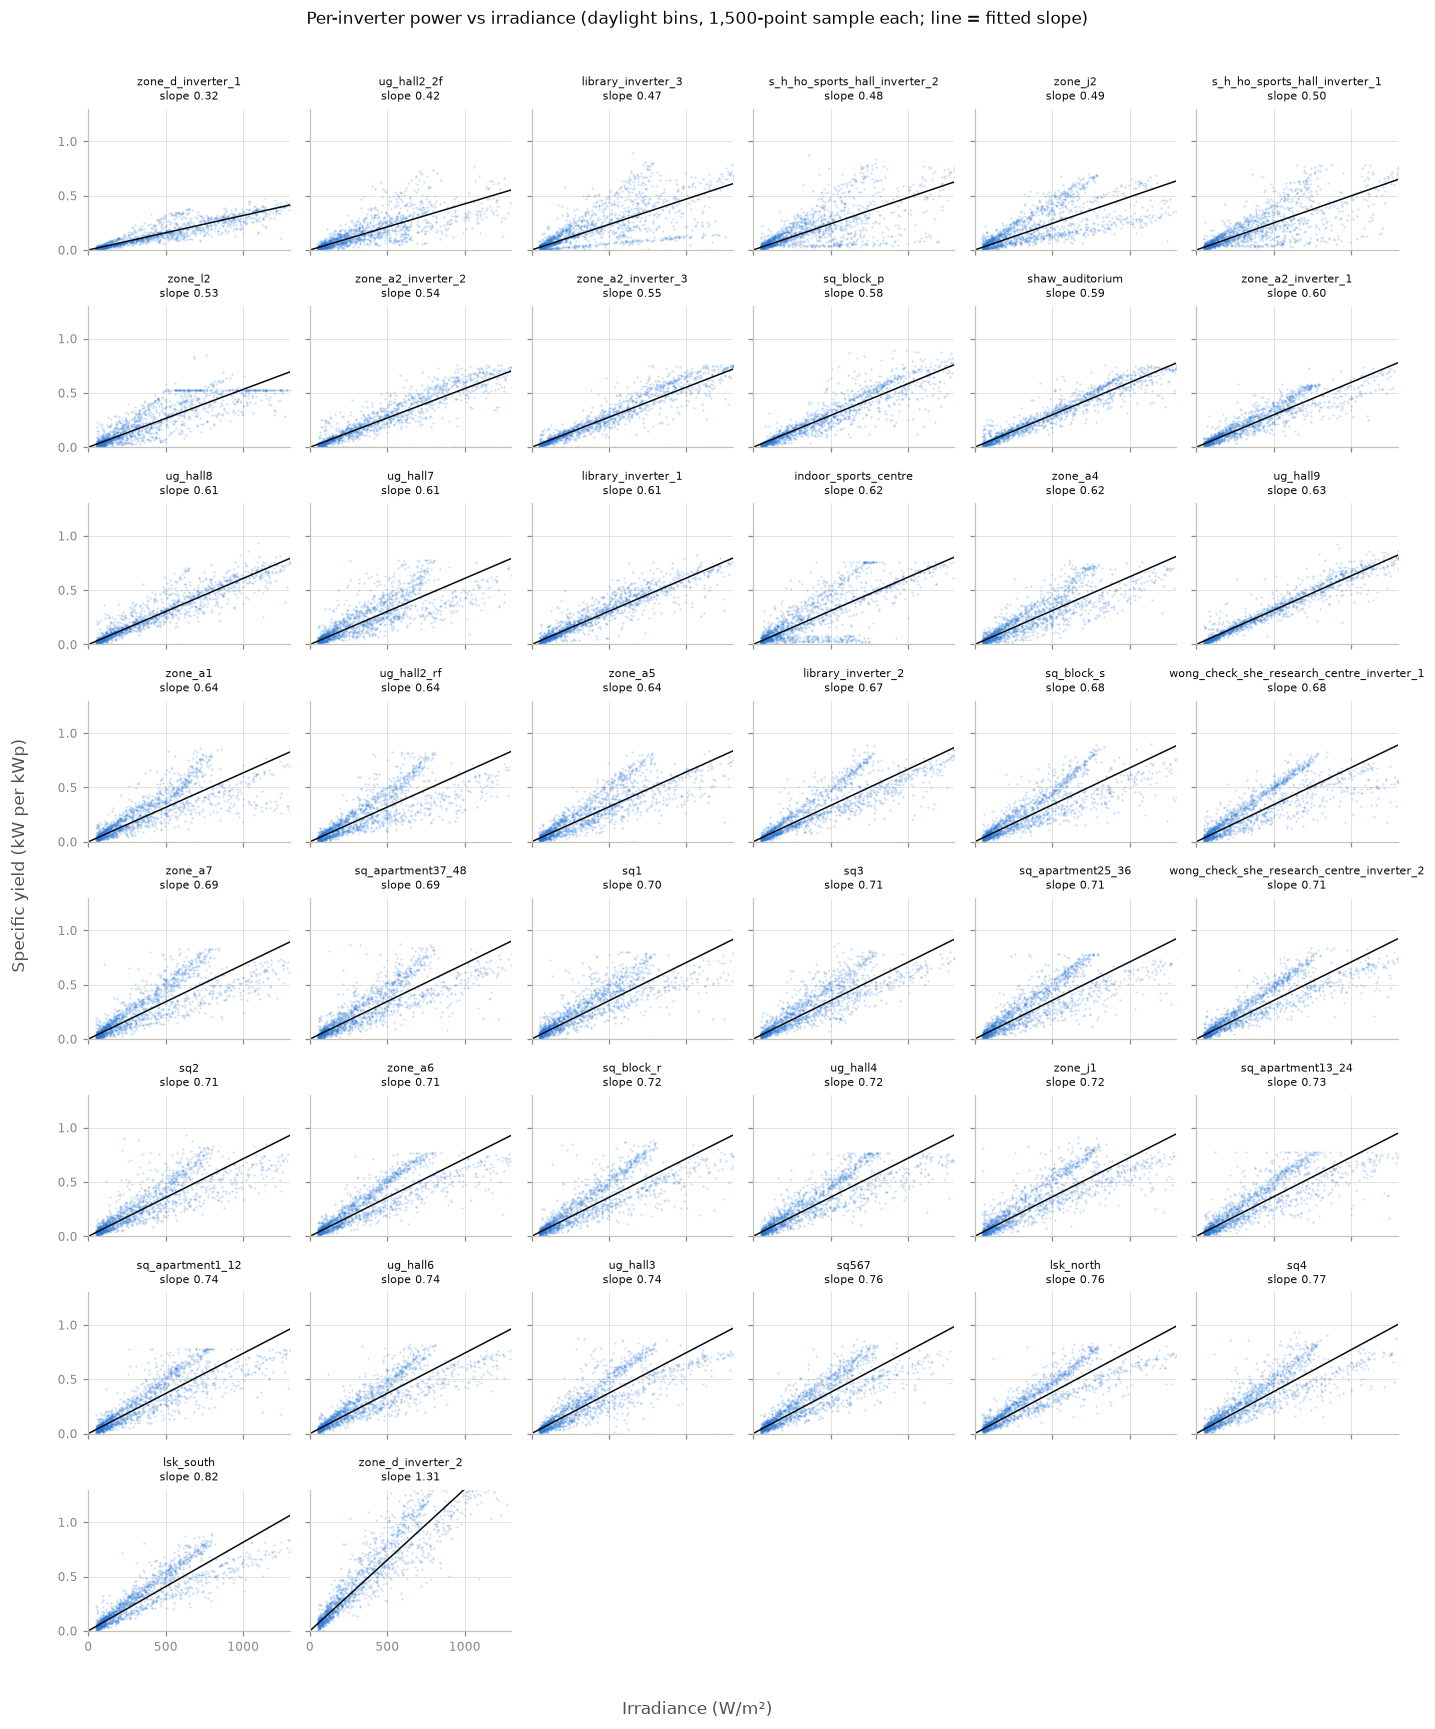

In [4]:
fig = eda.plot_per_inverter_grid(df, fits)
eda.save(fig, "a1_q1_per_inverter");

**Finding.**
- Most inverters have a slope of **0.6-0.8 kW/kWp per 1000 W/m²** and r of 0.8-0.95.
- **Zone D Inverter 2 is physically impossible:** slope 1.31, 99th percentile 1.63 kW/kWp, and a maximum AC power of 50.1 kW on a SolarEdge SE25K (25 kW) inverter. Its metadata capacity (25.74 kWp) is wrong, or the two Zone D files or capacities are swapped. **Zone D Inverter 1** (slope 0.32) is the other half of that problem.
- **Indoor Sports Centre is fine** (slope 0.62). Its 43.8 kWp capacity is consistent with the data, so the "10 kW inverter" model in the metadata is the error, not the capacity.
- Low r (about 0.68-0.75): Library Inverter 3, S H Ho Sports Hall 1 and 2, Zone J2, UG Hall2 2F. Their scatters show a second low branch, which suggests partial shading, mixed orientation or partial faults. They are worth checking against B1's health labels.

**Decision.** Raise Zone D with the team before capacity is used in PR or specific-yield features. Options are to correct the capacity from observed peak output, or to exclude Zone D.

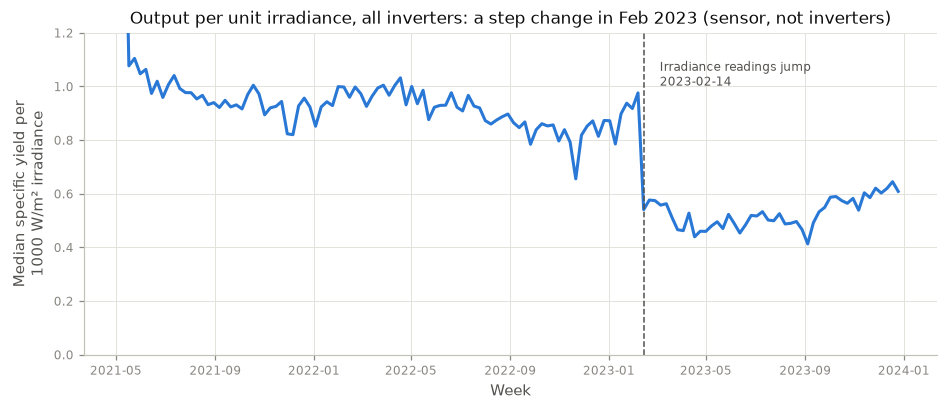

In [5]:
weekly = eda.weekly_yield_ratio(df)
fig = eda.plot_weekly_yield_ratio(weekly)
eda.save(fig, "a1_q1_irradiance_sensor_shift");

**Finding: the irradiance sensor changes on 2023-02-14.**
- Output per unit irradiance drops from about 0.85-0.95 to about 0.5 for **all inverters in the same week**, while PV output itself does not change.
- Daily peak irradiance jumps from about 600-840 W/m² (winter, before) to 1,150-1,560 W/m² from 2023-02-14. That day also has a physically impossible spike of **3,609 W/m²**.
- Annual maximum irradiance is 1,021 W/m² (2021), 1,093 W/m² (2022) and 3,609 W/m² (2023).

So the sensor was most likely replaced or recalibrated. Irradiance before and after 2023-02-14 is **not on the same scale**.

**Decision (affects the whole team).** 2023 is our test year. Any feature built on raw irradiance would make every inverter look about 45% worse in the test year. That includes PR, expected power and self-relative deviation. Options to agree on with A2 and B1:
1. Rescale irradiance after 2023-02-14 by a factor fitted on the weeks around the change.
2. Rely on **peer deviation** (inverter vs campus median at the same time), which does not use irradiance at all.
3. Add a sensor-period indicator feature.

The 3,609 W/m² spike is caught by A2's > 1,500 W/m² outlier rule.

,irr_bin,n_bins,share_producing,median_yield,q25_yield,q75_yield
0,0,20093,0.053850,0.000000,0.000000,0.000000
1,5,20451,0.422718,0.000000,0.000000,0.000970
2,10,18797,0.675959,0.001389,0.000000,0.004128
3,15,26525,0.727691,0.003436,0.000000,0.008392
4,20,30206,0.745117,0.005736,0.000000,0.012784
5,25,27883,0.836424,0.008585,0.001628,0.018190
6,30,29618,0.913836,0.014117,0.004946,0.025244
7,35,29573,0.941163,0.019214,0.008871,0.031599
8,40,26321,0.961058,0.023604,0.012663,0.037243
9,45,28138,0.983901,0.028044,0.015925,0.042492


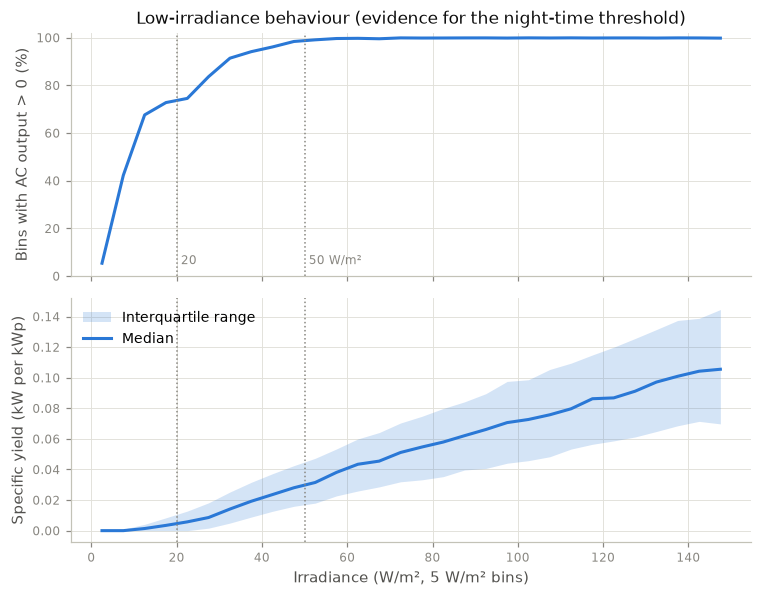

In [6]:
profile = eda.low_irradiance_profile(df)
fig = eda.plot_low_irradiance(profile)
eda.save(fig, "a1_q1_low_irradiance")
profile[profile["irr_bin"] <= 60]

**Finding.**
- Below 5 W/m², only about 5% of bins have any output.
- At 20-25 W/m², about 75% do.
- From **50 W/m²** upward, **99%** do.

**Decision.** This supports **50 W/m²** as the night-time threshold (A2, Stage 4). Below it, output is unreliable and carries no health information. It is also the daylight threshold already used for coverage in `prepare_data.py`. Caveat: the threshold was set on the pre-2023 sensor scale. On the new scale the same physical light reads higher, so the cut-off is a little stricter in 2023.

## Q2. Gaps and offline events

A **missing bin** is a 15-min bin with no valid power reading (`n_valid_5min == 0`). The raw files already contain every 06:00-17:45 bin, so gaps show up as `NA` rows, not as missing rows.

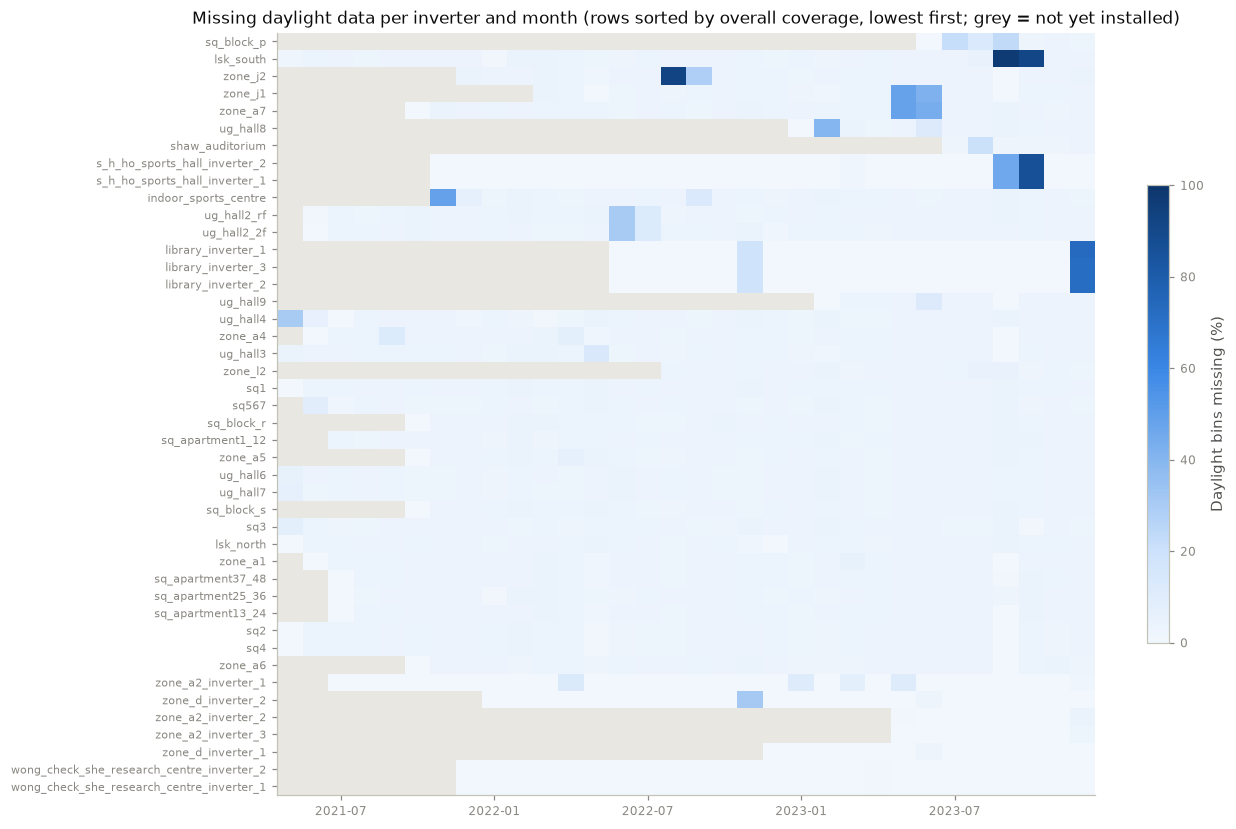

In [7]:
fig = eda.plot_gap_heatmap()
eda.save(fig, "a1_q2_gap_heatmap");

**Finding.**
- Most inverter-months have a background of about **4% missing**.
- A few **long outages** stand out: LSK South in Sep-Oct 2023, Zone J2 in Aug 2022, S H Ho Sports Hall in Sep-Oct 2023, and Library in Dec 2023.
- Several outages **hit inverters at the same time**: all 3 Library inverters, both S H Ho inverters, and Zone J1 with Zone A7 in May-Jun 2023. This points to communication or network failures rather than individual inverter faults.

**Decision.**
- A long outage is a real health event, so it should become `is_offline`, not be imputed.
- Shared outages are a **data-collection** failure. B1 and B2 should decide whether those count as "Faulty" or are excluded from the labels.
- Several of these outages fall in 2023, the test year.

,gap_length,n_runs,pct_of_runs,missing_bins,pct_of_missing_bins
0,15 min,75,7.1,75,0.2
1,30 min-1 h,46,4.4,120,0.2
2,1-4 h,45,4.3,431,0.9
3,4-12 h,823,78.5,31843,66.0
4,> 12 h (multi-day),60,5.7,15779,32.7


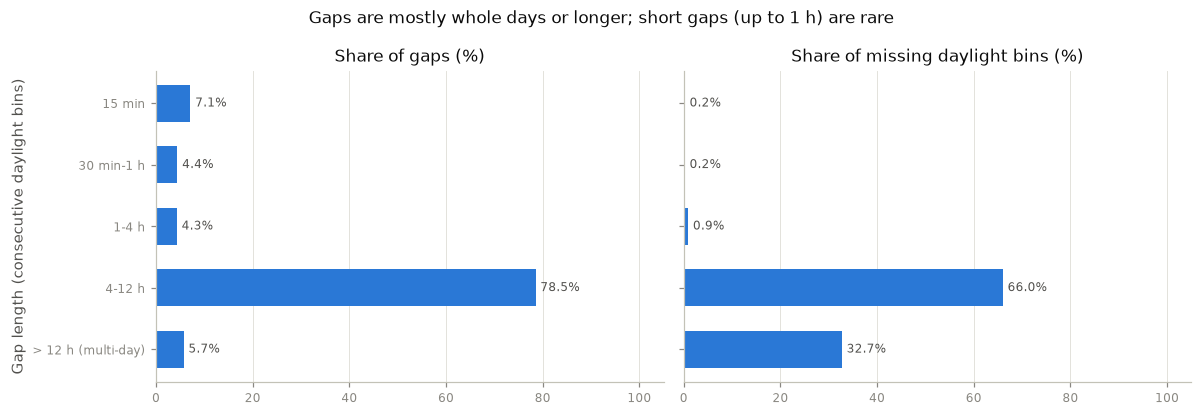

In [8]:
runs = eda.gap_runs(df)
summary = eda.gap_run_summary(runs)
fig = eda.plot_gap_runs(summary)
eda.save(fig, "a1_q2_gap_lengths")
summary

In [9]:
runs.sort_values("length_bins", ascending=False).head(10)

,inverter_id,start,end,length_bins
146,lsk_south_inverter,2023-09-06 09:30:00,2023-10-20 13:15:00,1561
989,zone_j2_inverter,2022-08-03 10:30:00,2022-09-08 09:45:00,1512
154,s_h_ho_sports_hall_inverter_2,2023-09-19 12:15:00,2023-10-27 16:45:00,1480
152,s_h_ho_sports_hall_inverter_1,2023-09-19 12:15:00,2023-10-27 16:45:00,1480
30,library_inverter_1,2023-12-04 14:15:00,2023-12-25 11:15:00,737
973,zone_j1_inverter,2023-06-12 06:00:00,2023-06-24 14:30:00,586
935,zone_a7_inverter,2023-06-12 12:45:00,2023-06-24 14:30:00,559
971,zone_j1_inverter,2023-05-04 13:15:00,2023-05-16 15:00:00,540
932,zone_a7_inverter,2023-05-04 13:15:00,2023-05-16 15:00:00,540
534,ug_hall2_2f_inverter,2022-06-23 09:45:00,2022-07-05 13:30:00,476


**Finding.**
- **78.5% of gaps last 4-12 daylight hours**, which is essentially a whole day, and hold 66% of all missing data.
- Multi-day gaps are only 5.7% of gaps but hold another 32.7% of missing data.
- Gaps of up to 1 hour are **11.5% of gaps and only 0.4% of missing data**.

**Decision.** A2's rule (interpolate gaps of 1 hour or less, flag longer ones as `is_offline`) is sound. Interpolation will affect very little data, so the choice of imputation method matters little. The offline flag carries almost all of the gap information.

,hour,pct_missing
0,6,28.21
1,7,4.92
2,8,3.76
3,9,3.75
4,10,3.81
5,11,3.81
6,12,3.82
7,13,3.82
8,14,3.84
9,15,3.82


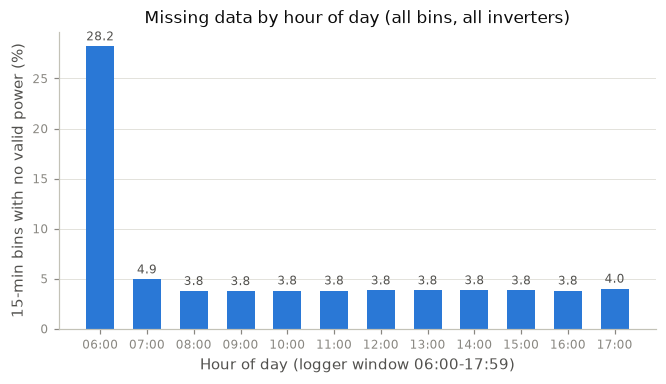

In [10]:
by_hour = eda.missing_by_hour(df)
fig = eda.plot_missing_by_hour(by_hour)
eda.save(fig, "a1_q2_missing_by_hour")
by_hour

**Finding.**
- The 06:00 hour is **28% missing**, against a steady **3.8%** for every other hour. Inverters are asleep before sunrise, especially in winter.
- The flat 3.8% is the whole-day outages, which show up equally in every hour.

**Decision.**
- 06:00 gaps are expected behaviour, not outages, so they must not count toward `is_offline`. The irradiance threshold above handles this.
- Coverage is measured on daylight bins only, as `prepare_data.py` already does.

## Summary for the team

| # | Finding | Who it affects |
|---|---|---|
| 1 | Irradiance sensor changes on **2023-02-14** (readings about 1.8x higher); raw-irradiance features are not comparable across the test year | A2, B1, B2 |
| 2 | **Zone D** capacities are inconsistent with the data (Inverter 2 reaches 50 kW on a 25 kW inverter) | B1 (PR features), A1 (metadata) |
| 3 | **50 W/m²** is where 99% of bins produce power, so it suits the night threshold | A2 |
| 4 | Gaps are almost all whole-day or multi-day; gaps of up to 1 h are 0.4% of missing data | A2 |
| 5 | Shared outages across inverters at the same station are data-collection failures, not faults | B1, B2 |
| 6 | Inverter clipping at about 0.75-0.8 kW/kWp | B1 (expected-power model) |